# Почему исчезает покрытие метаданных

## Эксперимент B · календарная диагностика

Предыдущие результаты сохранены коммитом `39f706d`. Проверяем typecode,
icaoaircrafttype, market_segment и AC_CLASS в исходном и финальном массивах.
Протокол: null и точная пустая строка — физический пропуск; остальные значения
сохраняем без исправлений. Отдельно показываем их словарь, поскольку непустая
строка не обязательно является содержательным классом.

Считаем объемы, GoA, пропуски по месяцу UTC, совместные шаблоны и
взаимоисключающие причины неполноты. Приоритет причины фиксирован:
typecode → icaoaircrafttype → market_segment → AC_CLASS. Это арифметическая
атрибуция потерь, не причина возникновения пропуска. Исходные данные не меняем.

[Карточка источника](https://zenodo.org/records/10210178) описывает метаданные
OpenSky / EUROCONTROL и поля market_segment, AC_CLASS. Она не устанавливает
историческое время получения каждого поля. Совпадение границы в источнике и
финале не доказывает механизм ошибки или изменение системы EUROCONTROL.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib,json
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from cycler import cycler
from IPython.display import display,Markdown
ROOT=Path.cwd().resolve()
while not (ROOT/'reports/verification.json').exists():
    if ROOT==ROOT.parent: raise FileNotFoundError('Нет отчета A')
    ROOT=ROOT.parent
R=ROOT/'reports'; F=ROOT/'figures'; PROJECT=ROOT.parents[1]
manifest=json.loads((R/'verification.json').read_text(encoding='utf-8'))
FIELDS=['typecode','icaoaircrafttype','market_segment','AC_CLASS']
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.spines.top':False,
 'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18,
 'axes.prop_cycle':cycler(color=['#D65A4A','#00897B','#E69A90','#80CBC4'])})
def sha(path):
    h=hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''): h.update(block)
    return h.hexdigest()
def save(name):
    plt.tight_layout()
    for ext in ['png','svg']: plt.savefig(F/f'{name}.{ext}',bbox_inches='tight')
    plt.show()
monthly=[]; patterns=[]; reasons=[]; boundaries=[]; values=[]; inputs=[]


## 1. Независимое чтение двух входов

Шаблон пропусков кодируется четырьмя битами в порядке FIELDS:
typecode=1, icaoaircrafttype=2, market_segment=4, AC_CLASS=8.
Нулевой шаблон означает физически полный набор. Даты ниже относятся к посадке,
а не к моменту появления информации в справочнике.

In [2]:
for stage in ['source','final']:
    entry=next(x for x in manifest['inputs'] if x['stage']==stage)
    path=PROJECT/entry['file'].replace(chr(92),'/')
    if not path.exists(): path=ROOT/'data'/Path(entry['file'].replace(chr(92),'/')).name
    assert sha(path)==entry['sha256']
    reader=pq.ParquetFile(path); chunks=[]; pattern_chunks=[]; reason_chunks=[]
    dictionaries={f:Counter() for f in FIELDS}; limits={f:[None,None] for f in FIELDS}
    n=0; positives=0
    for batch in reader.iter_batches(batch_size=200000,columns=['landing_time','airport','GoA']+FIELDS):
        d=batch.to_pandas(); n+=len(d); positives+=int(d.GoA.sum())
        month=d.landing_time.dt.strftime('%Y-%m')
        mask=pd.DataFrame({f:d[f].isna() | d[f].eq('').fillna(False) for f in FIELDS})
        q=pd.DataFrame({'month':month,'rows':1,'goa':d.GoA.astype(int)})
        for f in FIELDS:
            q[f+'_missing']=mask[f].astype(int)
            q[f+'_missing_goa']=(mask[f]&d.GoA).astype(int)
            present=d.loc[~mask[f],'landing_time']
            if len(present):
                lo,hi=present.min(),present.max()
                limits[f][0]=lo if limits[f][0] is None else min(lo,limits[f][0])
                limits[f][1]=hi if limits[f][1] is None else max(hi,limits[f][1])
            # Публикуем частоты, сохраняя пустую строку и null отдельными категориями.
            raw=d[f].fillna('<NULL>').replace('','<EMPTY>')
            for period,sel in [('all',pd.Series(True,index=d.index)),('2023',d.landing_time.dt.year.eq(2023))]:
                for value,count in raw[sel].value_counts().items(): dictionaries[f][(period,value)]+=int(count)
        chunks.append(q.groupby('month').sum().reset_index())
        pattern=sum(mask[f].astype(int)*(1<<i) for i,f in enumerate(FIELDS))
        q=pd.DataFrame({'month':month,'airport':d.airport,'pattern':pattern,'rows':1,'goa':d.GoA.astype(int)})
        pattern_chunks.append(q.groupby(['month','airport','pattern'],dropna=False)[['rows','goa']].sum().reset_index())
        reason=np.select([mask[f].to_numpy(dtype=bool) for f in FIELDS],FIELDS,default='complete')
        q=pd.DataFrame({'month':month,'reason':reason,'rows':1,'goa':d.GoA.astype(int)})
        reason_chunks.append(q.groupby(['month','reason'])[['rows','goa']].sum().reset_index())
    del reader
    assert n==entry['rows']; assert sha(path)==entry['sha256']
    m=pd.concat(chunks).groupby('month').sum().reset_index(); m['stage']=stage; monthly.append(m)
    p=pd.concat(pattern_chunks).groupby(['month','airport','pattern'],dropna=False)[['rows','goa']].sum().reset_index()
    p['stage']=stage; patterns.append(p)
    q=pd.concat(reason_chunks).groupby(['month','reason'])[['rows','goa']].sum().reset_index()
    q['stage']=stage; reasons.append(q)
    for f,(lo,hi) in limits.items():
        boundaries.append({'stage':stage,'field':f,'first_present_landing':str(lo),'last_present_landing':str(hi)})
        for (period,value),count in dictionaries[f].items():
            values.append({'stage':stage,'field':f,'period':period,'raw_value':value,'rows':count})
    inputs.append({'stage':stage,'sha256':entry['sha256'],'rows':n,'goa':positives,'input_unchanged':True})
monthly=pd.concat(monthly,ignore_index=True); patterns=pd.concat(patterns,ignore_index=True)
reasons=pd.concat(reasons,ignore_index=True); boundaries=pd.DataFrame(boundaries); values=pd.DataFrame(values)
for name,table in [('monthly',monthly),('patterns',patterns),('exclusive_reasons',reasons),('boundaries',boundaries),('value_counts',values)]:
    table.to_csv(R/f'metadata_{name}.csv',index=False)
display(boundaries)
display(monthly[monthly.month.ge('2022-12')].style.format(precision=0))


,stage,field,first_present_landing,last_present_landing
0,source,typecode,2019-01-01 00:56:00+00:00,2023-05-30 23:58:59+00:00
1,source,icaoaircrafttype,2019-01-01 00:56:00+00:00,2023-05-30 23:58:59+00:00
2,source,market_segment,2019-01-01 02:34:54+00:00,2023-01-01 10:44:36+00:00
3,source,AC_CLASS,2019-01-01 00:56:00+00:00,2023-05-30 23:58:59+00:00
4,final,typecode,2019-01-01 00:56:00+00:00,2023-05-30 23:58:59+00:00
5,final,icaoaircrafttype,2019-01-01 00:56:00+00:00,2023-05-30 23:58:59+00:00
6,final,market_segment,2019-01-01 02:34:54+00:00,2023-01-01 10:44:36+00:00
7,final,AC_CLASS,2019-01-01 00:56:00+00:00,2023-05-30 23:58:59+00:00


,month,rows,goa,typecode_missing,typecode_missing_goa,icaoaircrafttype_missing,icaoaircrafttype_missing_goa,market_segment_missing,market_segment_missing_goa,AC_CLASS_missing,AC_CLASS_missing_goa,stage
47,2022-12,98044,355,25187,94,26152,99,4836,28,28580,121,source
48,2023-01,173045,633,45109,174,46666,182,172913,633,51127,219,source
49,2023-02,129573,424,36294,149,37408,152,129573,424,42373,180,source
50,2023-03,153984,599,44294,185,45807,191,153984,599,46613,220,source
51,2023-04,164575,552,49415,177,50876,181,164575,552,51779,222,source
52,2023-05,171048,602,52245,219,53717,227,171048,602,53754,229,source
100,2022-12,69459,233,3019,9,3909,12,3299,13,0,0,final
101,2023-01,121918,414,5035,12,6432,18,121818,414,0,0,final
102,2023-02,87200,244,3908,17,4921,20,87200,244,0,0,final
103,2023-03,107371,379,4633,20,6029,26,107371,379,0,0,final


## 2. Поля по календарю

Штриховая линия — исходный массив, сплошная — финал. Все проценты используют
свой знаменатель этапа; разница не оценивает качество модели.

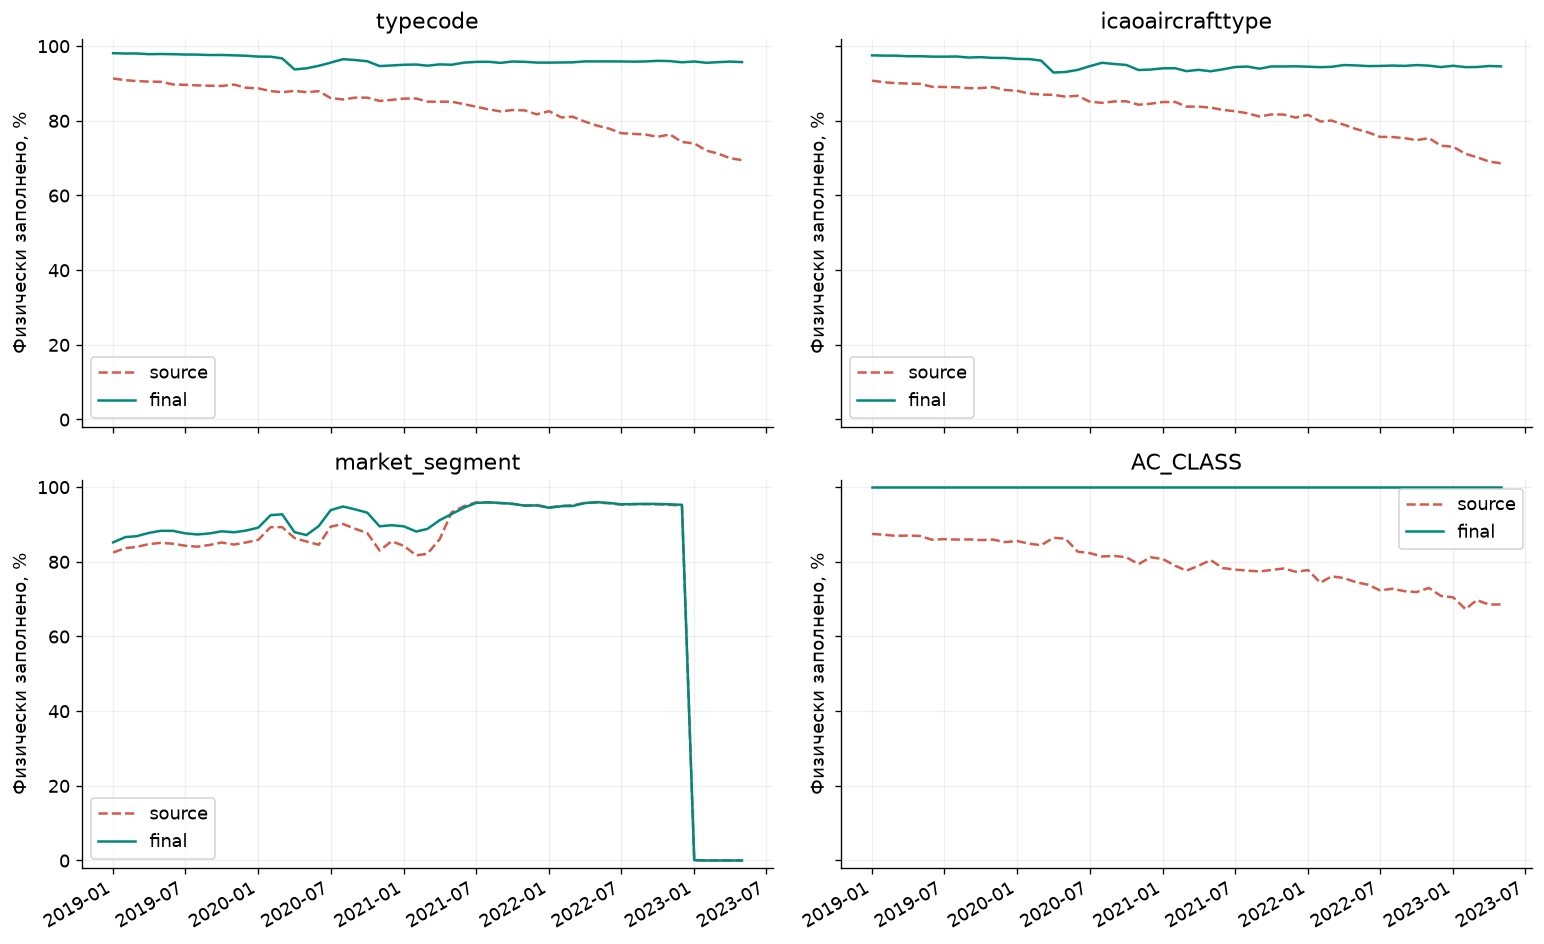

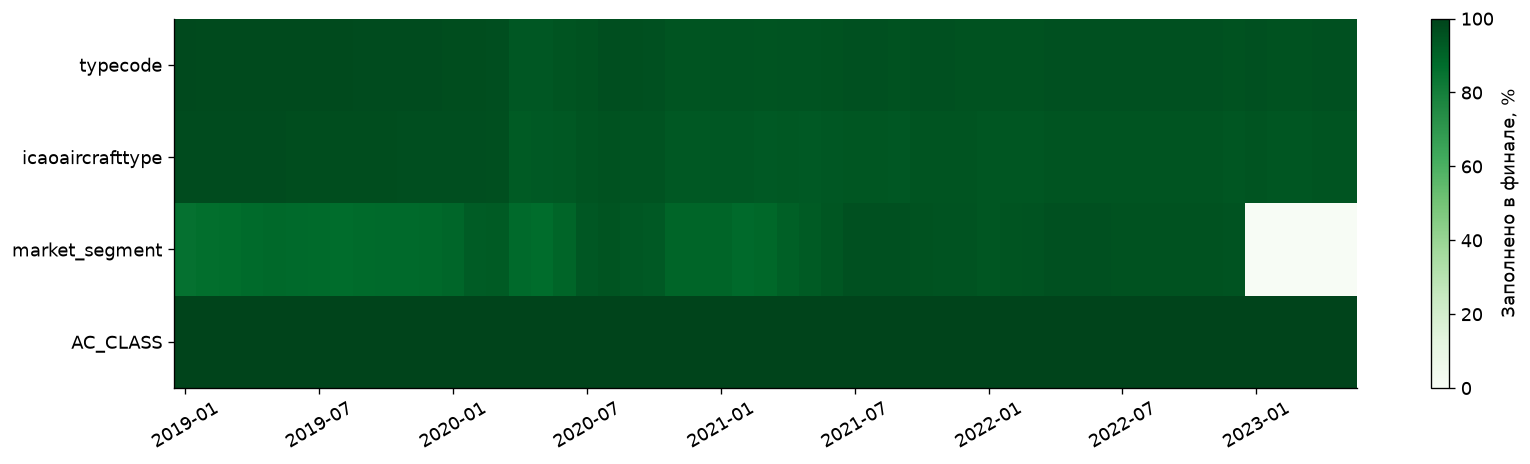

In [3]:
fig,axes=plt.subplots(2,2,figsize=(13,8),sharex=True,sharey=True)
for ax,f in zip(axes.flat,FIELDS):
    for stage,color,style in [('source','#D65A4A','--'),('final','#00897B','-')]:
        a=monthly[monthly.stage==stage].sort_values('month')
        ax.plot(pd.to_datetime(a.month),100*(1-a[f+'_missing']/a.rows),color=color,linestyle=style,label=stage)
    ax.set_title(f); ax.set_ylim(-2,102); ax.set_ylabel('Физически заполнено, %'); ax.legend()
fig.autofmt_xdate(); save('17_metadata_calendar_fields')
final=monthly[monthly.stage=='final'].set_index('month')
rates=pd.DataFrame({f:100*(1-final[f+'_missing']/final.rows) for f in FIELDS})
fig,ax=plt.subplots(figsize=(14,4))
im=ax.imshow(rates.T,aspect='auto',vmin=0,vmax=100,cmap='Greens')
ax.set_yticks(range(4),FIELDS); ticks=np.arange(0,len(rates),6)
ax.set_xticks(ticks,rates.index[ticks],rotation=30); ax.grid(False)
fig.colorbar(im,ax=ax,label='Заполнено в финале, %'); save('18_metadata_field_heatmap')


## 3. Какие требования исключают записи

Приоритет исключающей причины позволяет суммировать потери без двойного счета.
Совместные шаблоны в полном экспорте сохраняют пересечения.

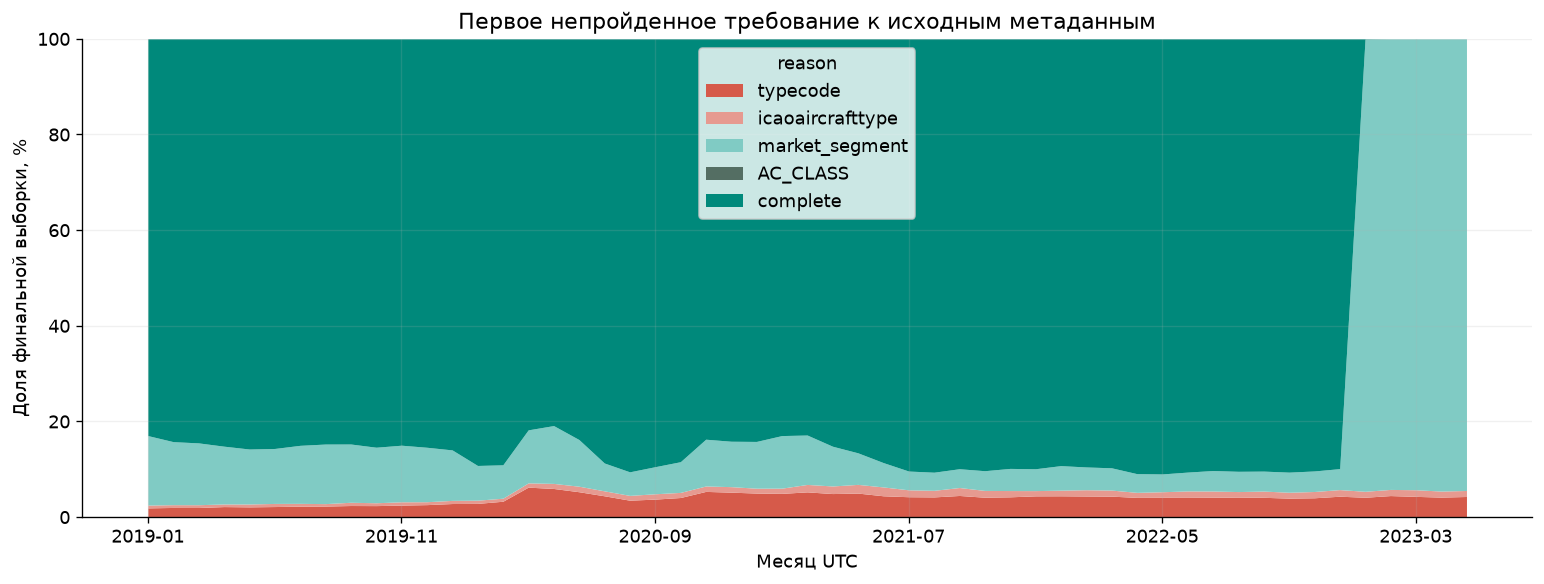

,stage,field,period,raw_value,rows
1390,final,AC_CLASS,2023,MJ,438852
1391,final,AC_CLASS,2023,H,95944
1392,final,AC_CLASS,2023,MT,7156
1393,final,AC_CLASS,2023,LJ,3399
1394,final,AC_CLASS,2023,LT,1034
1395,final,AC_CLASS,2023,ZZ,147
1396,final,AC_CLASS,2023,LP,46
1340,final,icaoaircrafttype,2023,L2J,500737
1341,final,icaoaircrafttype,2023,<NULL>,29780
1342,final,icaoaircrafttype,2023,L4J,7419


rows  goa
month   pattern             
2023-01 0            92    0
        3             8    0
        4        115273  396
        5           121    0
        6          1518    6
        7          4906   12
2023-02 4         82171  224
        5           108    0
        6          1121    3
        7          3800   17
2023-03 4        101250  353
        5            92    0
        6          1488    6
        7          4541   20
2023-04 4        106679  311
        5           101    0
        6          1427    4
        7          4589   15
2023-05 4        110789  345
        5           122    0
        6          1473    7
        7          4909   20

In [4]:
q=reasons[reasons.stage=='final'].pivot(index='month',columns='reason',values='rows').fillna(0)
q=q.reindex(columns=FIELDS+['complete'],fill_value=0)
(100*q.div(q.sum(axis=1),axis=0)).plot.area(figsize=(13,5),
    color=['#D65A4A','#E69A90','#80CBC4','#546E63','#00897B'],linewidth=0)
plt.ylabel('Доля финальной выборки, %'); plt.xlabel('Месяц UTC'); plt.ylim(0,100)
plt.title('Первое непройденное требование к исходным метаданным')
save('19_metadata_exclusive_losses')
display(values[(values.stage=='final') & (values.period=='2023')].sort_values(['field','rows'],ascending=[True,False]).groupby('field').head(8))
display(patterns[(patterns.stage=='final') & patterns.month.ge('2023-01')].groupby(['month','pattern'])[['rows','goa']].sum())


## 4. Балансы и интерпретация

Проверяем согласованность с четвертым ноутбуком. AC_CLASS без физических
пропусков не объявляется содержательно подтвержденным: словарь значений требует
источника кодов. Выбор признаков должен учитывать календарную поддержку и
доказательства исторической доступности одновременно.

In [5]:
coverage=pd.read_csv(R/'temporal_scenario_coverage.csv').set_index('scenario')
for entry in inputs:
    stage=entry['stage']; m=monthly[monthly.stage==stage]
    assert int(m.rows.sum())==entry['rows'] and int(m.goa.sum())==entry['goa']
    for table in [patterns,reasons]:
        a=table[table.stage==stage].groupby('month')[['rows','goa']].sum().sort_index()
        pd.testing.assert_frame_equal(a,m.set_index('month')[['rows','goa']].sort_index())
full=patterns[(patterns.stage=='final') & patterns.pattern.eq(0)]
assert int(full.rows.sum())==coverage.loc['raw_metadata_bundle','rows']
assert int(full.goa.sum())==coverage.loc['raw_metadata_bundle','goa']
audit={'inputs':inputs,'balances_passed':True,'scenario_matches_notebook04':True,
       'fields':FIELDS,'training_performed':False,'new_exclusions_applied':False}
(R/'metadata_verification.json').write_text(json.dumps(audit,indent=2),encoding='utf-8')
zero=monthly[monthly.market_segment_missing.eq(monthly.rows)][['stage','month','rows','goa']]
zero.to_csv(R/'metadata_market_segment_zero_months.csv',index=False)
text=f"""# Календарный аудит метаданных

Проверены исходный и финальный файлы, SHA256 до и после чтения одинаков.
Полные месяцы без физически заполненного market_segment:

{zero.to_string(index=False)}

Последние непустые значения по датам посадки:

{boundaries.to_string(index=False)}

Полный набор метаданных в финале: {int(full.rows.sum()):,} записей / {int(full.goa.sum()):,} GoA.
Все месячные балансы и сопоставление с ноутбуком 04 прошли проверку.
Непустые коды не подтверждают содержательную правильность или время доступности.
Сырые значения и совместные шаблоны опубликованы отдельно; данные не изменялись.
Причина возникновения пропусков по этим агрегатам не установлена.

Следующий шаг: сохранить сценарий без market_segment как отдельный кандидат,
уточнить историческое происхождение полей и подготовить протокол временного
разделения. Полный набор не следует применять как универсальное требование
до проверки календарной поддержки. Новые исключения и обучение не выполнялись.
"""
(R/'metadata_findings.md').write_text(text,encoding='utf-8'); display(Markdown(text))


# Календарный аудит метаданных

Проверены исходный и финальный файлы, SHA256 до и после чтения одинаков.
Полные месяцы без физически заполненного market_segment:

 stage   month   rows  goa
source 2023-02 129573  424
source 2023-03 153984  599
source 2023-04 164575  552
source 2023-05 171048  602
 final 2023-02  87200  244
 final 2023-03 107371  379
 final 2023-04 112796  330
 final 2023-05 117293  372

Последние непустые значения по датам посадки:

 stage            field     first_present_landing      last_present_landing
source         typecode 2019-01-01 00:56:00+00:00 2023-05-30 23:58:59+00:00
source icaoaircrafttype 2019-01-01 00:56:00+00:00 2023-05-30 23:58:59+00:00
source   market_segment 2019-01-01 02:34:54+00:00 2023-01-01 10:44:36+00:00
source         AC_CLASS 2019-01-01 00:56:00+00:00 2023-05-30 23:58:59+00:00
 final         typecode 2019-01-01 00:56:00+00:00 2023-05-30 23:58:59+00:00
 final icaoaircrafttype 2019-01-01 00:56:00+00:00 2023-05-30 23:58:59+00:00
 final   market_segment 2019-01-01 02:34:54+00:00 2023-01-01 10:44:36+00:00
 final         AC_CLASS 2019-01-01 00:56:00+00:00 2023-05-30 23:58:59+00:00

Полный набор метаданных в финале: 5,065,392 записей / 14,705 GoA.
Все месячные балансы и сопоставление с ноутбуком 04 прошли проверку.
Непустые коды не подтверждают содержательную правильность или время доступности.
Сырые значения и совместные шаблоны опубликованы отдельно; данные не изменялись.
Причина возникновения пропусков по этим агрегатам не установлена.

Следующий шаг: сохранить сценарий без market_segment как отдельный кандидат,
уточнить историческое происхождение полей и подготовить протокол временного
разделения. Полный набор не следует применять как универсальное требование
до проверки календарной поддержки. Новые исключения и обучение не выполнялись.
